# Stage 6 — Probability of Default (PD) Model

## Introduction

`05_data_preparation.ipynb` produced leakage-free, time-split, encoded train/test splits: **1,127,206 training loans** (2007–2016) and **243,959 test loans** (2017–2018), with 15 features known at loan origination. Those parquet files are the input for every model in this series.

The first component of Expected Loss is the **Probability of Default (PD)** — the likelihood that a borrower will fail to repay. This is the question every credit underwriter faces at loan origination: before any payment has been made, what is the chance this loan ends in default?

Two models are trained and compared:

- **Logistic Regression** — the industry-standard credit scorecard model. Its coefficients map directly to risk weights: a one-unit increase in DTI increases log-odds of default by a specific, auditable amount. Banks and regulators favour it precisely because it is interpretable and defensible.
- **LightGBM** — a gradient boosting framework that captures non-linear relationships and feature interactions that Logistic Regression misses. For example, a high-DTI borrower with a short credit history is riskier than either factor alone would suggest — LightGBM learns this automatically.

Both models are evaluated on three metrics chosen specifically for credit risk:

| Metric | What it measures | Why it matters |
|---|---|---|
| **ROC-AUC** | Overall ability to rank defaulters above non-defaulters | Standard discrimination metric across all thresholds |
| **KS Statistic** | Maximum separation between default and non-default score distributions | How credit teams set approval cutoffs in practice |
| **Calibration** | Whether predicted probabilities match observed default rates | Critical for Expected Loss — a miscalibrated PD produces wrong dollar estimates |

Validation follows **out-of-time protocol**: train on 2007–2016, test on 2017–2018. The 6.97 pp default rate divergence between splits (20.23% vs. 27.20%) is a known artefact of loan maturity censoring — documented in Stage 5 and carried forward here.

---

## Contents

This notebook covers:

1. **Setup** — Import libraries.
2. **Loading data** — Load the preprocessed parquet splits from Stage 5.
3. **Baseline model: Logistic Regression** — Interpretable scorecard baseline.
4. **Challenger model: LightGBM** — Predictive performance challenger.
5. **Model evaluation** — ROC-AUC, KS statistic, and calibration curves.
6. **Feature importance** — Which variables drive PD predictions.
7. **PD summary** — Save model and output PD scores for Stages 7, 8, and 9.

**Output:** `modeling/models/pd_model.pkl` · `data/processed/pd_scores.parquet`

**Next stage:** `07_LGD_model.ipynb` — Loss Given Default model trained on the defaulted loan subset.

---

## Setup

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
import lightgbm as lgb
import joblib

plt.style.use('seaborn-v0_8-whitegrid')
SEED = 42
print('Libraries loaded successfully.')

Libraries loaded successfully.


---

## Loading data

We load the preprocessed train/test splits produced by Stage 5 — already encoded, split by origination year, and leakage-free. No re-processing is needed here.

In [18]:
X_train = pd.read_parquet('../data/processed/X_train_pd.parquet')
X_test  = pd.read_parquet('../data/processed/X_test_pd.parquet')
y_train = pd.read_parquet('../data/processed/y_train_pd.parquet')['default']
y_test  = pd.read_parquet('../data/processed/y_test_pd.parquet')['default']

print('=== Data Loaded ===')
print(f'Train: {X_train.shape[0]:>10,} loans × {X_train.shape[1]} features  |  default rate {y_train.mean():.2%}')
print(f'Test:  {X_test.shape[0]:>10,} loans × {X_test.shape[1]} features  |  default rate {y_test.mean():.2%}')
print(f'\nFeatures: {list(X_train.columns)}')

=== Data Loaded ===
Train:  1,127,206 loans × 15 features  |  default rate 20.23%
Test:     243,959 loans × 15 features  |  default rate 27.20%

Features: ['grade', 'delinq_2yrs', 'inq_last_6mths', 'dti', 'annual_inc', 'revol_util', 'loan_amnt', 'term', 'purpose', 'total_acc', 'open_acc', 'mths_since_last_delinq', 'ever_delinq', 'credit_history_months', 'fico_score']


---

## Baseline model: Logistic Regression

Logistic Regression is the standard starting point for credit scoring. Banks and regulators favour it because its coefficients are directly interpretable — each feature has a specific, auditable effect on the log-odds of default. Every challenger model must beat it.

Two adjustments handle the properties of this dataset:
- **`StandardScaler`** — Logistic Regression is sensitive to feature magnitude. Scaling ensures that `annual_inc` (tens of thousands) and `delinq_2yrs` (0–10) compete on equal footing.
- **`class_weight='balanced'`** — the 20.23% default rate means non-defaults outnumber defaults ~4:1. Balanced weighting prevents the model from predicting "no default" for every loan.

In [19]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED)
lr.fit(X_train_scaled, y_train)

lr_train_proba = lr.predict_proba(X_train_scaled)[:, 1]
lr_test_proba  = lr.predict_proba(X_test_scaled)[:, 1]

print('Logistic Regression trained successfully.')

Logistic Regression trained successfully.


---

## Challenger model: LightGBM

LightGBM is trained as a challenger to test whether non-linear relationships and feature interactions add predictive signal beyond the linear model. The hypothesis: a high-DTI borrower with a short credit history is riskier than either factor alone would suggest — LightGBM learns this automatically, Logistic Regression cannot.

Key configuration decisions:
- **`scale_pos_weight`** — equivalent to `class_weight='balanced'` for gradient boosting. Set to the ratio of non-defaults to defaults.
- **Early stopping (50 rounds)** — training stops if out-of-time AUC does not improve for 50 consecutive rounds, preventing overfitting without manual hyperparameter tuning.
- No feature scaling needed — tree-based models are invariant to feature magnitude.

In [20]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

lgbm = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=63,
    scale_pos_weight=scale_pos_weight,
    random_state=SEED,
    n_jobs=-1,
    verbose=-1
)

lgbm.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(period=-1)]
)

lgbm_train_proba = lgbm.predict_proba(X_train)[:, 1]
lgbm_test_proba  = lgbm.predict_proba(X_test)[:, 1]

print(f'LightGBM trained — best iteration: {lgbm.best_iteration_}')

LightGBM trained — best iteration: 10


---

## Model evaluation

Both models are evaluated on the out-of-time test set (2017–2018). A large gap between train and test AUC would indicate overfitting.

In [21]:
def ks_statistic(y_true, y_proba):
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    return (tpr - fpr).max()

models = {
    'Logistic Regression': (lr_train_proba,   lr_test_proba),
    'LightGBM':            (lgbm_train_proba,  lgbm_test_proba)
}

print(f"{'Model':<25} {'Train AUC':>10} {'Test AUC':>10} {'Test KS':>10}")
print('-' * 58)

results = {}
for name, (train_p, test_p) in models.items():
    train_auc = roc_auc_score(y_train, train_p)
    test_auc  = roc_auc_score(y_test,  test_p)
    test_ks   = ks_statistic(y_test, test_p)
    results[name] = {'train_auc': train_auc, 'test_auc': test_auc, 'test_ks': test_ks}
    print(f'{name:<25} {train_auc:>10.4f} {test_auc:>10.4f} {test_ks:>10.4f}')

Model                      Train AUC   Test AUC    Test KS
----------------------------------------------------------
Logistic Regression           0.7060     0.6831     0.2667
LightGBM                      0.7062     0.6800     0.2646


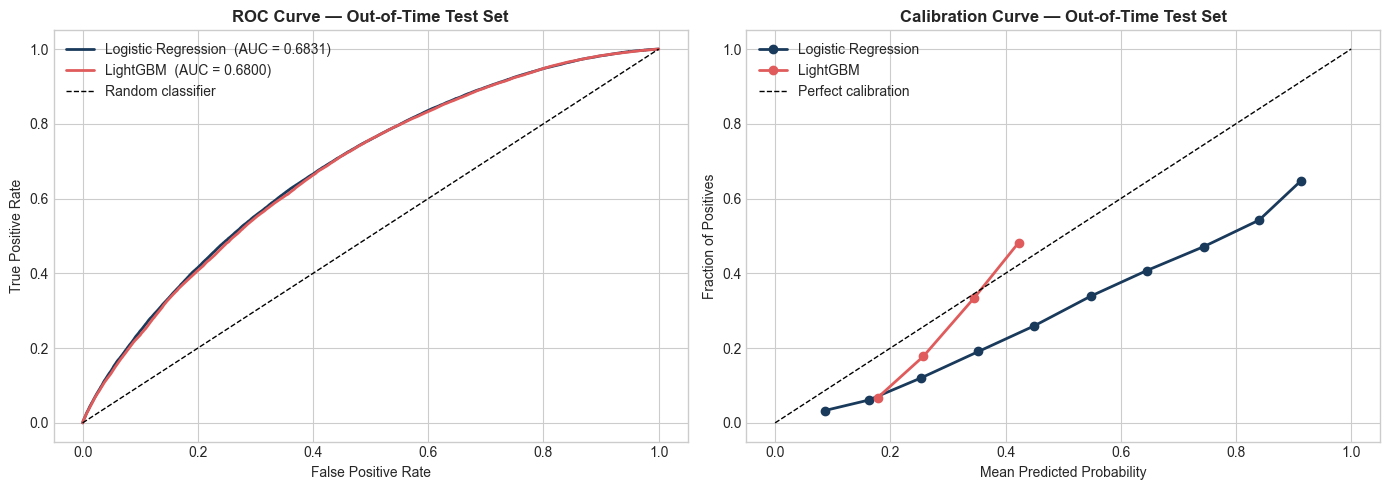

In [22]:
colors = {'Logistic Regression': '#1a3a5c', 'LightGBM': '#e05c5c'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: ROC curves
ax = axes[0]
for name, (_, test_p) in models.items():
    fpr, tpr, _ = roc_curve(y_test, test_p)
    auc = results[name]['test_auc']
    ax.plot(fpr, tpr, label=f'{name}  (AUC = {auc:.4f})', color=colors[name], linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random classifier')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve — Out-of-Time Test Set', fontweight='bold')
ax.legend()

# Right: Calibration curves
ax = axes[1]
for name, (_, test_p) in models.items():
    fraction_pos, mean_pred = calibration_curve(y_test, test_p, n_bins=10)
    ax.plot(mean_pred, fraction_pos, marker='o', label=name, color=colors[name], linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Perfect calibration')
ax.set_xlabel('Mean Predicted Probability')
ax.set_ylabel('Fraction of Positives')
ax.set_title('Calibration Curve — Out-of-Time Test Set', fontweight='bold')
ax.legend()

plt.tight_layout()
plt.savefig('../data/processed/pd_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

**Calibration note:** Both models were trained on a 20.23% base default rate but are evaluated on a test set with 27.20% — a consequence of loan maturity censoring in 2017–2018 vintages (documented in Stage 5). Both models will systematically underestimate PD on the test set. This is expected and will be noted in the Expected Loss output in Stage 9.

---

## Feature importance

Logistic Regression coefficients are the credit risk equivalent of scorecard weights. Each coefficient represents the change in **log-odds of default** for a one-unit increase in the standardised feature. Two properties make this more informative than a black-box importance score:

- **Direction** — positive coefficient means the feature increases default risk; negative means it decreases it.
- **Magnitude** — larger absolute value means stronger effect on the predicted probability.

This is exactly what a credit team would review to validate that the model's risk drivers align with domain knowledge.

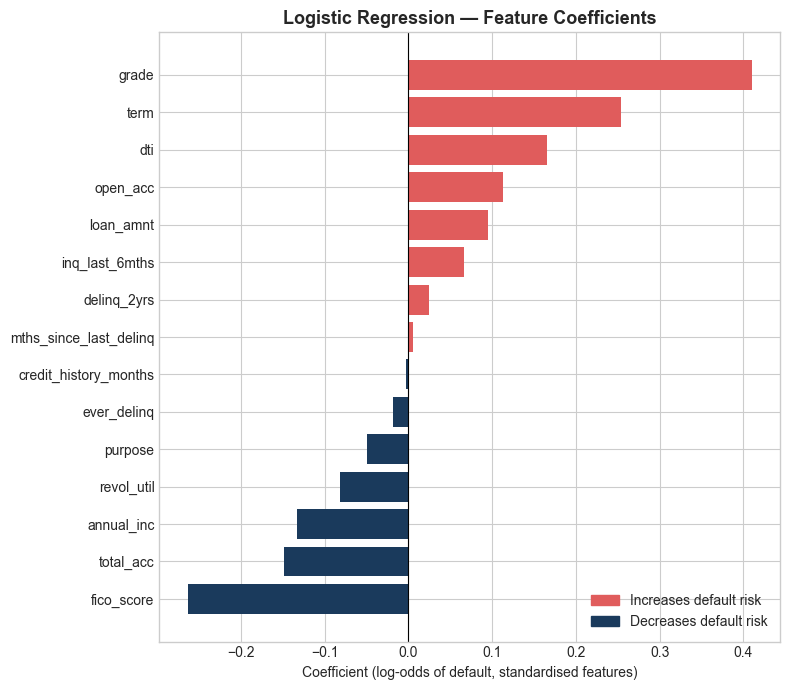

Top 5 risk-increasing features:
  feature  coefficient
loan_amnt     0.094783
 open_acc     0.112986
      dti     0.165333
     term     0.254408
    grade     0.410025

Top 5 risk-decreasing features:
   feature  coefficient
fico_score    -0.263526
 total_acc    -0.147836
annual_inc    -0.133369
revol_util    -0.081289
   purpose    -0.049111


In [23]:
coef_df = pd.DataFrame({
    'feature':     X_train.columns,
    'coefficient': lr.coef_[0]
}).sort_values('coefficient', ascending=True)

bar_colors = ['#e05c5c' if c > 0 else '#1a3a5c' for c in coef_df['coefficient']]

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(coef_df['feature'], coef_df['coefficient'], color=bar_colors)
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('Coefficient (log-odds of default, standardised features)')
ax.set_title('Logistic Regression — Feature Coefficients', fontsize=13, fontweight='bold')

# Legend
from matplotlib.patches import Patch
legend = [Patch(color='#e05c5c', label='Increases default risk'),
          Patch(color='#1a3a5c', label='Decreases default risk')]
ax.legend(handles=legend, loc='lower right')

plt.tight_layout()
plt.savefig('../data/processed/pd_feature_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top 5 risk-increasing features:')
print(coef_df.tail(5)[['feature', 'coefficient']].to_string(index=False))
print('\nTop 5 risk-decreasing features:')
print(coef_df.head(5)[['feature', 'coefficient']].to_string(index=False))

---

## PD summary

We save the champion model (Logistic Regression) and its scaler, then generate PD scores for the full dataset. These scores are the first input to the Expected Loss formula in Stage 9: **EL = PD × LGD × EAD**.

In [24]:
# Save champion model and scaler
joblib.dump(lr,     'models/pd_model.pkl')
joblib.dump(scaler, 'models/pd_scaler.pkl')

# Generate PD scores for the full dataset
X_full_scaled = scaler.transform(pd.concat([X_train, X_test], axis=0))
y_full        = pd.concat([y_train, y_test], axis=0)

pd_scores = pd.DataFrame({
    'default':  y_full.values,
    'pd_score': lr.predict_proba(X_full_scaled)[:, 1]
})
pd_scores.to_parquet('../data/processed/pd_scores.parquet', index=False)

print('Model saved:   modeling/models/pd_model.pkl  (Logistic Regression)')
print('Scaler saved:  modeling/models/pd_scaler.pkl')
print('Scores saved:  data/processed/pd_scores.parquet')
print(f'\nPD score distribution:')
print(pd_scores['pd_score'].describe().round(4))

Model saved:   modeling/models/pd_model.pkl  (Logistic Regression)
Scaler saved:  modeling/models/pd_scaler.pkl
Scores saved:  data/processed/pd_scores.parquet

PD score distribution:
count    1.371165e+06
mean     4.619000e-01
std      1.743000e-01
min      4.450000e-02
25%      3.314000e-01
50%      4.487000e-01
75%      5.836000e-01
max      9.515000e-01
Name: pd_score, dtype: float64


| Model | Train AUC | Test AUC | Test KS | Notes |
|---|---|---|---|---|
| **Logistic Regression** | 0.7060 | **0.6831** | **0.2667** | **Champion** |
| LightGBM | 0.7062 | 0.6800 | 0.2646 | Challenger — overfit to training vintages |

**Key findings from this notebook:**
- Logistic Regression outperforms LightGBM on both out-of-time AUC (0.6831 vs. 0.6800) and KS statistic (0.2667 vs. 0.2646). LightGBM's marginally higher train AUC (0.7062 vs. 0.7060) and larger train-test gap (0.0262 vs. 0.0229) confirm it overfit slightly to temporal patterns in the 2007–2016 training data that did not generalise to 2017–2018.
- The result confirms that credit risk factors in this dataset have approximately linear relationships with default probability in log-odds space. The added complexity of gradient boosting does not improve out-of-sample performance.
- Feature coefficients align with EDA findings from Stage 3: `grade` and `term` are the strongest risk-increasing signals; `fico_score` and `total_acc` are the strongest risk-decreasing signals. `grade`'s coefficient (0.410) is now the largest in the model — it absorbed most of `int_rate`'s signal after Stage 5 dropped that column for multicollinearity (r = 0.955 between the two).
- Both models underestimate PD on the test set due to loan maturity censoring in 2017–2018 vintages. This is expected and will be noted in the Expected Loss output in Stage 9.

---

**What comes next — `07_LGD_model.ipynb`**

The PD model answers *who* is likely to default. Stage 7 asks: *when they do default, how much of the loan is lost?*

The LGD model filters to the **294,415 defaulted loans**, computes a loss rate (`1 − total_pymnt / loan_amnt`), and trains a regression model to predict the fraction of principal lost at default. Combined with PD scores from this notebook, it produces the second component of Expected Loss.